# Домашнее задание 4: Регрессия на California Housing



In [1]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 1. Загрузка и первичный анализ данных

In [2]:
california_data = fetch_california_housing(as_frame=True)
df = california_data.frame

print('Размер датасета:', df.shape)
print('\nПропуски:')
print(df.isnull().sum())

display(df.head())

Размер датасета: (20640, 9)

Пропуски:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300,4.5260
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200,3.5850
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400,3.5210
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500,3.4130
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500,3.4220


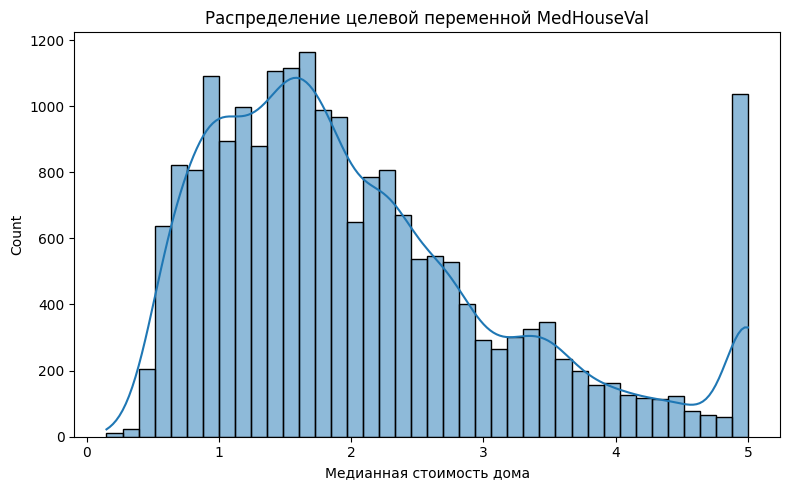

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], bins=40, kde=True, ax=ax)
ax.set_title('Распределение целевой переменной MedHouseVal')
ax.set_xlabel('Медианная стоимость дома')
plt.tight_layout()
plt.show()

## 2. Train/test split и масштабирование

In [4]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Обучающая выборка:', X_train_scaled.shape)
print('Тестовая выборка:', X_test_scaled.shape)

Обучающая выборка: (16512, 8)
Тестовая выборка: (4128, 8)


## 3. Обучение моделей и оценка

In [5]:
results = []

# 3.1 Линейная регрессия
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
pred_lin = lin_reg.predict(X_test_scaled)
results.append({
    'model': 'LinearRegression',
    'params': '-',
    'test_rmse': np.sqrt(mean_squared_error(y_test, pred_lin))
})

# 3.2 Ridge с подбором alpha
ridge_params = {'alpha': [0.1, 1.0, 10.0]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=3, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
pred_ridge = ridge_grid.predict(X_test_scaled)
results.append({
    'model': 'Ridge (best)',
    'params': f"alpha={ridge_grid.best_params_['alpha']}",
    'test_rmse': np.sqrt(mean_squared_error(y_test, pred_ridge))
})

# 3.3 Lasso с подбором alpha
lasso_params = {'alpha': [0.0001, 0.001, 0.01]}
lasso_grid = GridSearchCV(Lasso(max_iter=20000), lasso_params, cv=3, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
pred_lasso = lasso_grid.predict(X_test_scaled)
results.append({
    'model': 'Lasso (best)',
    'params': f"alpha={lasso_grid.best_params_['alpha']}",
    'test_rmse': np.sqrt(mean_squared_error(y_test, pred_lasso))
})

# 3.4 RandomForest
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append({
    'model': 'RandomForest',
    'params': 'n_estimators=200',
    'test_rmse': np.sqrt(mean_squared_error(y_test, pred_rf))
})

results_df = pd.DataFrame(results).sort_values('test_rmse')
display(results_df)
print(f"\nЛучшая модель: {results_df.iloc[0]['model']} с RMSE = {results_df.iloc[0]['test_rmse']:.4f}")

,model,params,test_rmse
3,RandomForest,n_estimators=200,0.5040
2,Lasso (best),alpha=0.001,0.7446
1,Ridge (best),alpha=1.0,0.7456
0,LinearRegression,-,0.7456



Лучшая модель: RandomForest с RMSE = 0.5040


## 4. Выводы

1. **LinearRegression** даёт базовое качество, но не учитывает нелинейности.
2. **Ridge** и **Lasso** с подбором `alpha` стабилизируют коэффициенты и обычно немного снижают ошибку, особенно если признаки коррелированы.
3. **RandomForestRegressor** обычно показывает лучший RMSE за счёт моделирования нелинейных зависимостей, но требует больше памяти и времени.
4. Масштабирование важно для линейных моделей; дереву оно не нужно, поэтому RF обучался на исходных признаках.

Если нужно ещё больше улучшить результат, можно добавить нелинейные признаки (например, отношения комнат к спальням), использовать `RandomForest` с подбором `max_depth`/`min_samples_leaf` или перейти на градиентный бустинг.